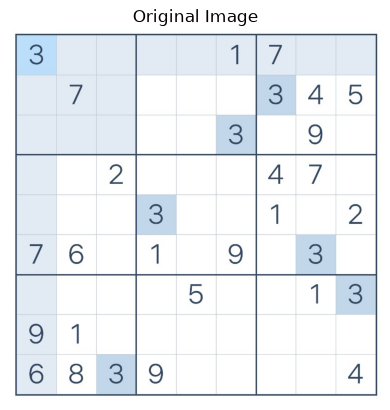

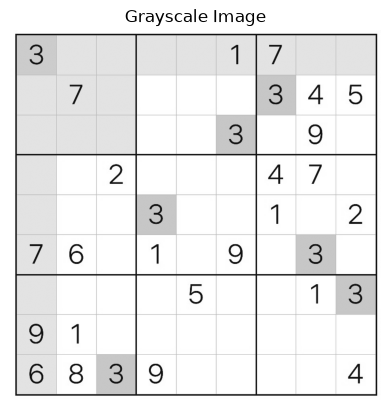

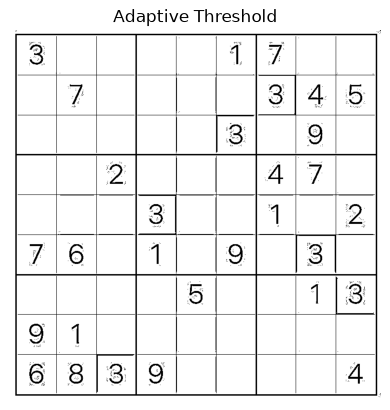

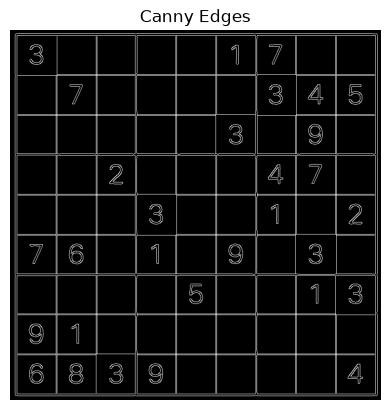

sudoku grid found
grid area: 561001.0


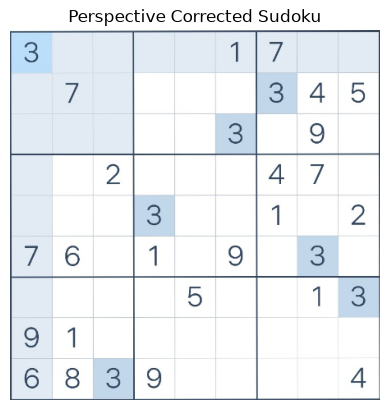

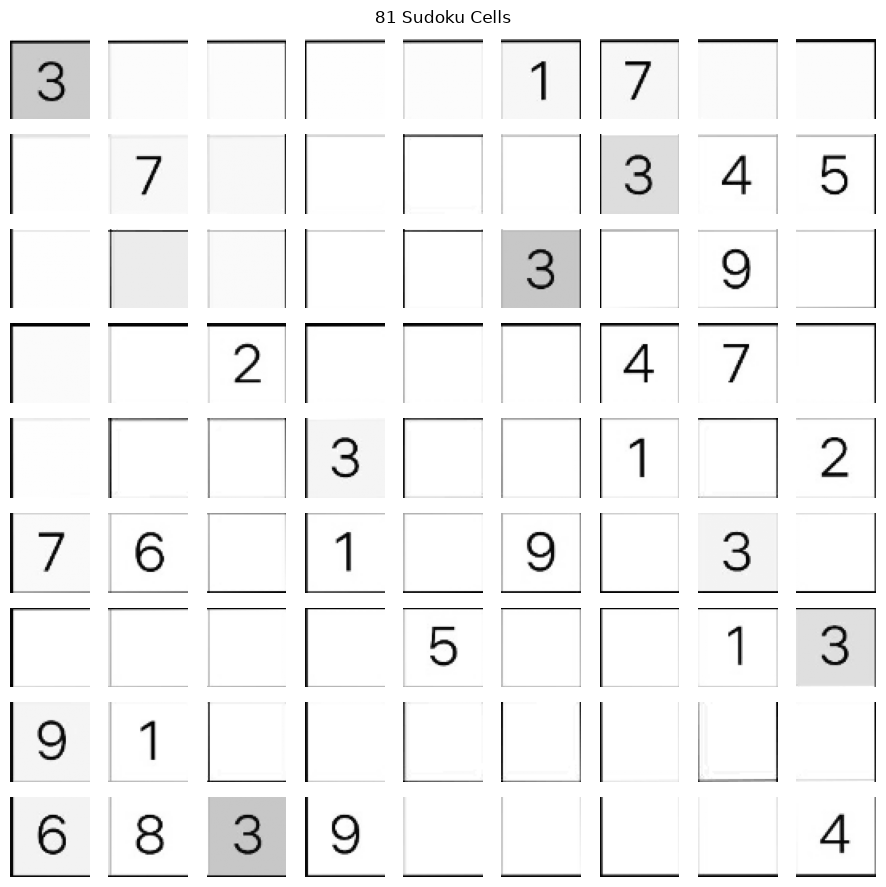

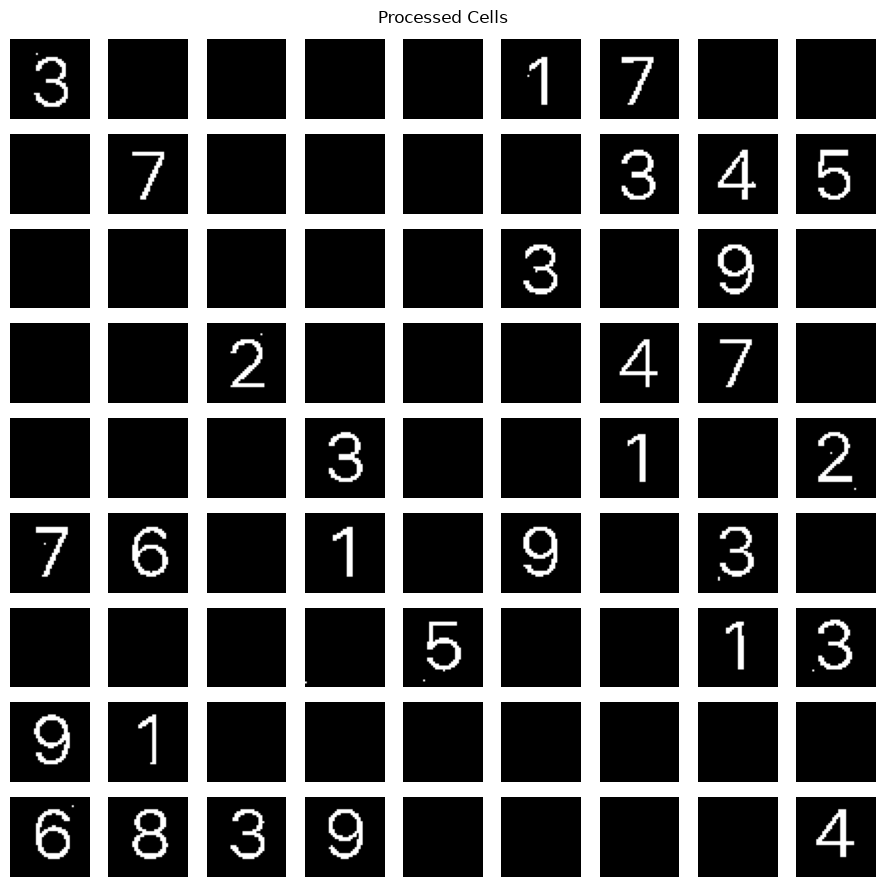


Recognised Sudoku:
0 = empty or unrecognised cell

[3, 0, 0, 0, 0, 1, 7, 0, 0]
[0, 7, 0, 0, 0, 0, 3, 4, 5]
[0, 0, 0, 0, 0, 3, 0, 9, 0]
[0, 0, 2, 0, 0, 0, 4, 7, 0]
[0, 0, 0, 3, 0, 0, 1, 0, 2]
[7, 6, 0, 1, 0, 9, 0, 3, 0]
[0, 0, 0, 0, 5, 0, 0, 1, 3]
[9, 1, 0, 0, 0, 0, 0, 0, 0]
[6, 8, 3, 9, 0, 0, 0, 0, 4]

Recognised 30 out of 81 cells.

Empty or unrecognised cells:
Row 1, column 2
Row 1, column 3
Row 1, column 4
Row 1, column 5
Row 1, column 8
Row 1, column 9
Row 2, column 1
Row 2, column 3
Row 2, column 4
Row 2, column 5
Row 2, column 6
Row 3, column 1
Row 3, column 2
Row 3, column 3
Row 3, column 4
Row 3, column 5
Row 3, column 7
Row 3, column 9
Row 4, column 1
Row 4, column 2
Row 4, column 4
Row 4, column 5
Row 4, column 6
Row 4, column 9
Row 5, column 1
Row 5, column 2
Row 5, column 3
Row 5, column 5
Row 5, column 6
Row 5, column 8
Row 6, column 3
Row 6, column 5
Row 6, column 7
Row 6, column 9
Row 7, column 1
Row 7, column 2
Row 7, column 3
Row 7, column 4
Row 7, column 6
Row 7, col

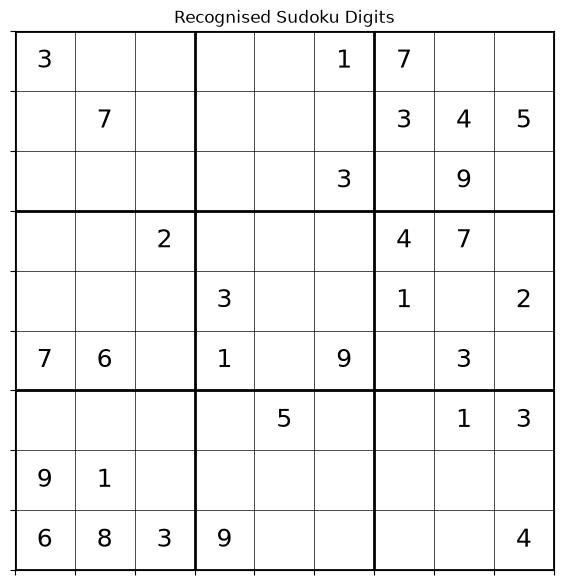


Foreground pixel count for each cell:

Row 1, Column 1: 139 pixels
Row 1, Column 2: 0 pixels
Row 1, Column 3: 0 pixels
Row 1, Column 4: 0 pixels
Row 1, Column 5: 0 pixels
Row 1, Column 6: 90 pixels
Row 1, Column 7: 101 pixels
Row 1, Column 8: 0 pixels
Row 1, Column 9: 0 pixels
Row 2, Column 1: 0 pixels
Row 2, Column 2: 93 pixels
Row 2, Column 3: 0 pixels
Row 2, Column 4: 0 pixels
Row 2, Column 5: 0 pixels
Row 2, Column 6: 0 pixels
Row 2, Column 7: 152 pixels
Row 2, Column 8: 144 pixels
Row 2, Column 9: 156 pixels
Row 3, Column 1: 0 pixels
Row 3, Column 2: 0 pixels
Row 3, Column 3: 0 pixels
Row 3, Column 4: 0 pixels
Row 3, Column 5: 0 pixels
Row 3, Column 6: 144 pixels
Row 3, Column 7: 0 pixels
Row 3, Column 8: 176 pixels
Row 3, Column 9: 0 pixels
Row 4, Column 1: 0 pixels
Row 4, Column 2: 0 pixels
Row 4, Column 3: 134 pixels
Row 4, Column 4: 0 pixels
Row 4, Column 5: 0 pixels
Row 4, Column 6: 0 pixels
Row 4, Column 7: 123 pixels
Row 4, Column 8: 92 pixels
Row 4, Column 9: 0 pixels
Row

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pytesseract

# Set the Tesseract executable path for Windows
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

# load the image
image = cv2.imread("sudoku.jpg")

if image is None:
    print("could not load image")
    raise SystemExit

# display original image
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Original Image")
plt.show()

# convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.title("Grayscale Image")
plt.show()

# apply adaptive thresholding
threshold = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, 11, 2
)
plt.imshow(threshold, cmap="gray")
plt.axis("off")
plt.title("Adaptive Threshold")
plt.show()

# detect edges
edges = cv2.Canny(gray, 50, 150)
plt.imshow(edges, cmap="gray")
plt.axis("off")
plt.title("Canny Edges")
plt.show()

# find contours
contours, hierarchy = cv2.findContours(
    edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# find the largest four-sided contour
largest_area = 0
grid = None

for contour in contours:
    perimeter = cv2.arcLength(contour, True)
    approximation = cv2.approxPolyDP(contour, 0.02 * perimeter, True)

    if len(approximation) == 4:
        area = cv2.contourArea(approximation)
        if area > largest_area:
            largest_area = area
            grid = approximation

if grid is None:
    print("could not find sudoku grid")
    raise SystemExit

print("sudoku grid found")
print("grid area:", largest_area)

# get the four corners
points = sorted(grid.reshape(4, 2), key=lambda p: p[1])
top_points = sorted(points[:2], key=lambda p: p[0])
bottom_points = sorted(points[2:], key=lambda p: p[0])
top_left = top_points[0]
top_right = top_points[1]
bottom_left = bottom_points[0]
bottom_right = bottom_points[1]

# set up perspective transformation
src = np.float32([top_left, top_right, bottom_right, bottom_left])
dst = np.float32([[0, 0], [450, 0], [450, 450], [0, 450]])
matrix = cv2.getPerspectiveTransform(src, dst)
warped = cv2.warpPerspective(image, matrix, (450, 450))

# display corrected sudoku
warped_rgb = cv2.cvtColor(warped, cv2.COLOR_BGR2RGB)
plt.imshow(warped_rgb)
plt.axis("off")
plt.title("Perspective Corrected Sudoku")
plt.show()

# split sudoku into 81 cells
cell_size = 450 // 9
cells = []

for row in range(9):
    row_cells = []
    for col in range(9):
        x1 = col * cell_size
        y1 = row * cell_size
        x2 = x1 + cell_size
        y2 = y1 + cell_size
        row_cells.append(warped[y1:y2, x1:x2])
    cells.append(row_cells)

# display the 81 cells
fig, axes = plt.subplots(9, 9, figsize=(9, 9))
for row in range(9):
    for col in range(9):
        cell_gray = cv2.cvtColor(cells[row][col], cv2.COLOR_BGR2GRAY)
        axes[row, col].imshow(cell_gray, cmap="gray")
        axes[row, col].axis("off")
plt.suptitle("81 Sudoku Cells")
plt.tight_layout()
plt.show()

# process each cell
processed_cells = []

for row in range(9):
    processed_row = []
    for col in range(9):
        cell_gray = cv2.cvtColor(cells[row][col], cv2.COLOR_BGR2GRAY)

        # remove cell border
        border = 5
        cell_gray = cell_gray[border:-border, border:-border]

        # threshold the cell
        cell_threshold = cv2.adaptiveThreshold(
            cell_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY_INV, 11, 2
        )
        processed_row.append(cell_threshold)
    processed_cells.append(processed_row)

# display processed cells
fig, axes = plt.subplots(9, 9, figsize=(9, 9))
for row in range(9):
    for col in range(9):
        axes[row, col].imshow(processed_cells[row][col], cmap="gray")
        axes[row, col].axis("off")
plt.suptitle("Processed Cells")
plt.tight_layout()
plt.show()

# recognise the digits in each cell
digit_grid = []
pixel_threshold = 25

for row in range(9):
    digit_row = []

    for col in range(9):
        cell = processed_cells[row][col]

        # Check whether the cell contains enough foreground pixels
        foreground_pixels = cv2.countNonZero(cell)
        if foreground_pixels <= pixel_threshold:
            digit_row.append(0)
            continue

        # Find the foreground regions in the processed cell
        contours, _ = cv2.findContours(
            cell.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )

        # Ignore tiny marks that are unlikely to be part of a digit
        useful_contours = [
            contour for contour in contours
            if cv2.contourArea(contour) >= 2
        ]

        if not useful_contours:
            digit_row.append(0)
            continue

        # Crop around all remaining foreground regions
        boxes = [cv2.boundingRect(contour) for contour in useful_contours]
        x_min = min(box[0] for box in boxes)
        y_min = min(box[1] for box in boxes)
        x_max = max(box[0] + box[2] for box in boxes)
        y_max = max(box[1] + box[3] for box in boxes)

        digit = cell[y_min:y_max, x_min:x_max]

        if digit.size == 0:
            digit_row.append(0)
            continue

        # Put the digit on a clean white background with dark text
        digit = cv2.bitwise_not(digit)

        # Enlarge the digit to give OCR more pixels to work with
        digit = cv2.resize(
            digit, None, fx=5, fy=5, interpolation=cv2.INTER_CUBIC
        )

        digit = cv2.copyMakeBorder(
            digit, 25, 25, 25, 25,
            cv2.BORDER_CONSTANT, value=255
        )

        # Trying a few OCR modes, as individual digits can be recognised differently 
        configs = [
            "--oem 3 --psm 10 -c tessedit_char_whitelist=123456789",
            "--oem 3 --psm 8 -c tessedit_char_whitelist=123456789",
            "--oem 3 --psm 13 -c tessedit_char_whitelist=123456789"
        ]

        recognised = 0

        for config in configs:
            result = pytesseract.image_to_string(
                digit, config=config
            ).strip()

            result = "".join(character for character in result
                             if character in "123456789")

            if result:
                recognised = int(result[0])
                break

        digit_row.append(recognised)

    digit_grid.append(digit_row)

# display the recognised Sudoku matrix
print()
print("Recognised Sudoku:")
print("0 = empty or unrecognised cell")
print()

for row in digit_grid:
    print(row)

recognised_count = sum(
    value != 0 for row in digit_grid for value in row
)
print(f"\nRecognised {recognised_count} out of 81 cells.")

print("\nEmpty or unrecognised cells:")
for row in range(9):
    for col in range(9):
        if digit_grid[row][col] == 0:
            print(f"Row {row + 1}, column {col + 1}")

# display the recognised numbers as a Sudoku grid
fig, ax = plt.subplots(figsize=(7, 7))
ax.set_xlim(0, 9)
ax.set_ylim(9, 0)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_aspect("equal")

for i in range(10):
    line_width = 2 if i % 3 == 0 else 0.5
    ax.axhline(i, linewidth=line_width, color="black")
    ax.axvline(i, linewidth=line_width, color="black")

for row in range(9):
    for col in range(9):
        value = digit_grid[row][col]
        if value != 0:
            ax.text(
                col + 0.5, row + 0.5, str(value),
                ha="center", va="center", fontsize=18
            )

plt.title("Recognised Sudoku Digits")
plt.show()

# display pixel counts to help tune the empty-cell threshold
print("\nForeground pixel count for each cell:\n")

for row in range(9):
    for col in range(9):
        foreground_pixels = cv2.countNonZero(processed_cells[row][col])
        print(
            f"Row {row + 1}, Column {col + 1}: "
            f"{foreground_pixels} pixels"
        )
